     customer name                                    customer e-mail  \
0    Martina Avila  cubilia.Curae.Phasellus@quisaccumsanconvallis.edu   
1    Harlan Barnes                                eu.dolor@diam.co.uk   
2  Naomi Rodriquez  vulputate.mauris.sagittis@ametconsectetueradip...   
3  Jade Cunningham                            malesuada@dignissim.com   
4     Cedric Leach     felis.ullamcorper.viverra@egetmollislectus.net   

        country  gender        age  annual Salary  credit card debt  \
0      Bulgaria       0  41.851720    62812.09301      11609.380910   
1        Belize       0  40.870623    66646.89292       9572.957136   
2       Algeria       1  43.152897    53798.55112      11160.355060   
3  Cook Islands       1  58.271369    79370.03798      14426.164850   
4        Brazil       1  57.313749    59729.15130       5358.712177   

     net worth  car purchase amount  
0  238961.2505          35321.45877  
1  530973.9078          45115.52566  
2  638467.1773      

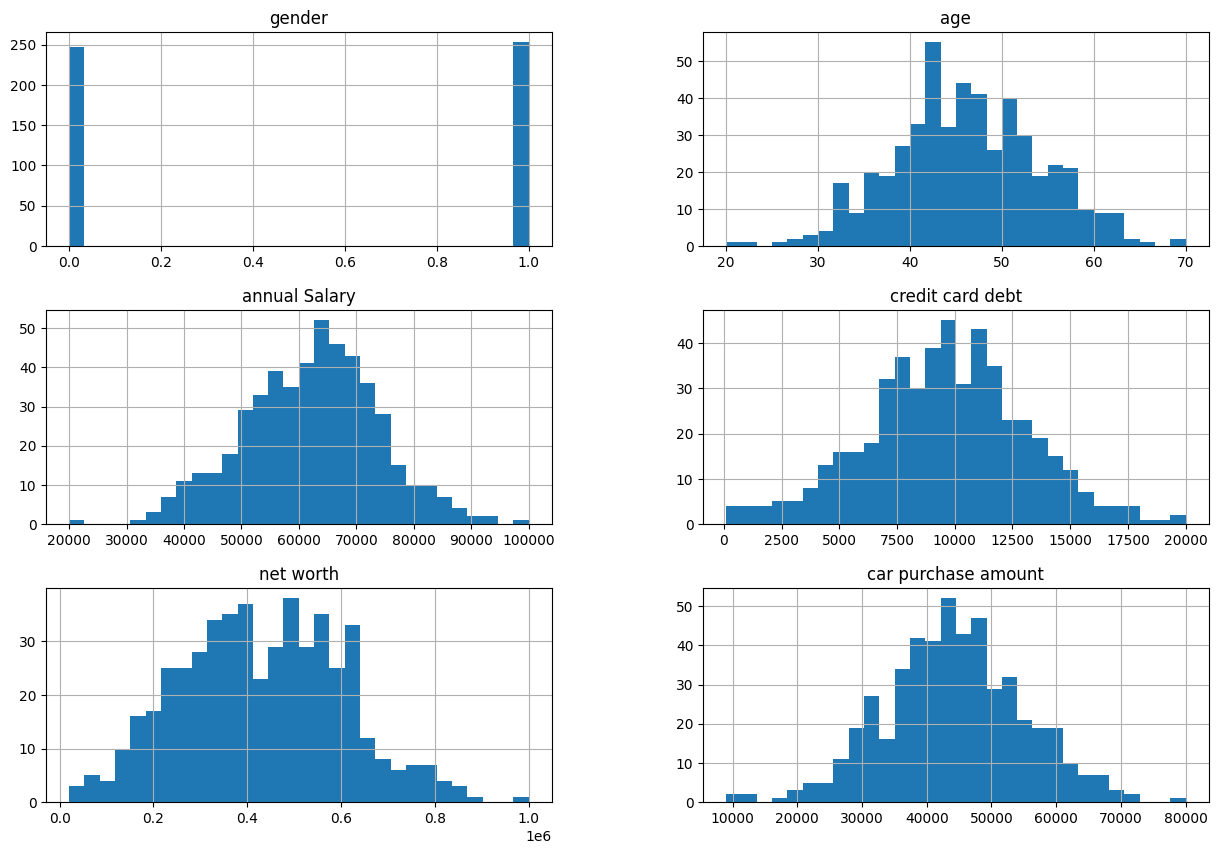

In [4]:
# Import necessary libraries
import pandas as pd  # For data handling
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For data visualization
import seaborn as sns  # For advanced data visualization

# Step 1: Load the dataset
data = pd.read_csv('/content/car_purchasing.csv', encoding='ISO-8859-1')

# Display the first few rows of the dataset to understand its structure
print(data.head())

# Step 2: Check for missing values
# Check for missing values across all columns
missing_values = data.isnull().sum()  # Counts missing values in each column
print(f'Missing Values:\n{missing_values}')

# Step 3: Basic data statistics
# Some basic statistics like mean, median, min, max, etc.
print(f'Dataset Statistics:\n{data.describe()}')

# Step 4: Check for duplicates
# Checking if there are any duplicate rows in the dataset
duplicates = data.duplicated().sum()
print(f'Duplicate Rows: {duplicates}')

# Step 5: Visualize the distribution of numeric columns
# Plotting histograms for each numerical column to see how the data is distributed
# bins=20 to split the range of values into 20 intervals.
data.hist(bins=30, figsize=(15, 10))
plt.show()

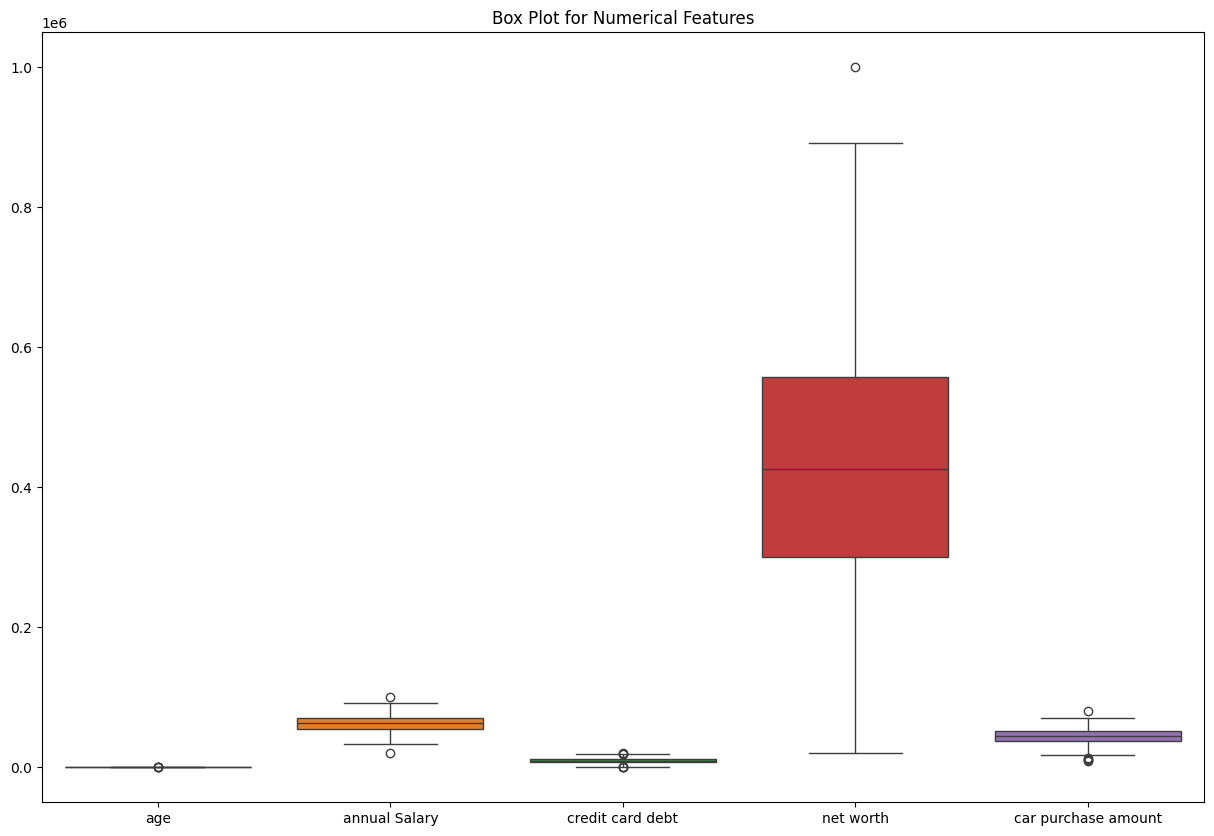

Outliers (Z-scores greater than 3 or less than -3):
age                    2
annual Salary          2
credit card debt       0
net worth              1
car purchase amount    3
dtype: int64
Rows with Outliers:
             customer name                          customer e-mail  \
28           Gemma Hendrix                       lobortis@non.co.uk   
37          Uriel Bradshaw              ultrices@Integersemelit.com   
89         Ferdinand Weber           metus.Vivamus@vitaeposuere.org   
315  Cameron, Kimberley P.                 nec.tellus@lacinia.co.uk   
444                 Camden  Aliquam.adipiscing.lobortis@loremut.net   
453                Tatyana         sem@parturientmontesnascetur.net   

                 country  gender        age  annual Salary  credit card debt  \
28               Denmark       1  46.124036   100000.00000      17452.921790   
37                Turkey       1  22.000387    43131.78411      10917.140940   
89              Suriname       1  32.094081    20000

In [5]:
# Importing necessary libraries for visualization
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

# Step 1: Visualize outliers using box plots
# Boxplots will show us the spread of data and help us see any outliers
plt.figure(figsize=(15, 10))
sns.boxplot(data=data[['age', 'annual Salary', 'credit card debt', 'net worth', 'car purchase amount']])
plt.title('Box Plot for Numerical Features')
plt.show()

# Step 2: Checking for outliers using Z-score
# Z-score helps us identify values that are too far away from the mean (outliers)
# Calculate the Z-score for each numerical column
z_scores = data[['age', 'annual Salary', 'credit card debt', 'net worth', 'car purchase amount']].apply(zscore)

# Step 3: Define threshold for outliers (common threshold is 3)
outliers = (z_scores > 3) | (z_scores < -3)
print("Outliers (Z-scores greater than 3 or less than -3):")
print(outliers.sum())

# Check for rows with outliers by filtering them
outlier_rows = data[outliers.any(axis=1)]
print("Rows with Outliers:")
print(outlier_rows)

In [6]:
# Step 1: Remove outliers using Z-score threshold of 3 (both positive and negative)
# Create a mask to filter out rows where any Z-score is greater than 3 or less than -3
filtered_data = data[(z_scores < 3).all(axis=1) & (z_scores > -3).all(axis=1)]

# Display the shape of the dataset before and after removing outliers
print(f'Original dataset shape: {data.shape}')
print(f'Dataset shape after removing outliers: {filtered_data.shape}')

# Optionally, display the first few rows of the cleaned dataset
print(filtered_data.head())

Original dataset shape: (500, 9)
Dataset shape after removing outliers: (494, 9)
     customer name                                    customer e-mail  \
0    Martina Avila  cubilia.Curae.Phasellus@quisaccumsanconvallis.edu   
1    Harlan Barnes                                eu.dolor@diam.co.uk   
2  Naomi Rodriquez  vulputate.mauris.sagittis@ametconsectetueradip...   
3  Jade Cunningham                            malesuada@dignissim.com   
4     Cedric Leach     felis.ullamcorper.viverra@egetmollislectus.net   

        country  gender        age  annual Salary  credit card debt  \
0      Bulgaria       0  41.851720    62812.09301      11609.380910   
1        Belize       0  40.870623    66646.89292       9572.957136   
2       Algeria       1  43.152897    53798.55112      11160.355060   
3  Cook Islands       1  58.271369    79370.03798      14426.164850   
4        Brazil       1  57.313749    59729.15130       5358.712177   

     net worth  car purchase amount  
0  238961.2505 

In [8]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Step 1: Encoding categorical variables
# Since 'gender' is categorical (0 for female, 1 for male), we can keep it as is.
# If there were other categorical variables, use LabelEncoder or OneHotEncoder.

# Step 2: Scaling numerical features
# Use StandardScaler to scale the numerical features
scaler = StandardScaler()

# Columns to scale (excluding non-numeric and already encoded columns like 'gender')
columns_to_scale = ['age', 'annual Salary', 'credit card debt', 'net worth', 'car purchase amount']

# Fit the scaler on the data and transform the numerical columns
filtered_data.loc[:,columns_to_scale] = scaler.fit_transform(filtered_data[columns_to_scale])

# Display the first few rows of the scaled data
print(filtered_data.head())

     customer name                                    customer e-mail  \
0    Martina Avila  cubilia.Curae.Phasellus@quisaccumsanconvallis.edu   
1    Harlan Barnes                                eu.dolor@diam.co.uk   
2  Naomi Rodriquez  vulputate.mauris.sagittis@ametconsectetueradip...   
3  Jade Cunningham                            malesuada@dignissim.com   
4     Cedric Leach     felis.ullamcorper.viverra@egetmollislectus.net   

        country  gender       age  annual Salary  credit card debt  net worth  \
0      Bulgaria       0 -0.585704       0.058274          0.583111  -1.120507   
1        Belize       0 -0.712111       0.395270         -0.006325   0.581954   
2       Algeria       1 -0.418057      -0.733822          0.453142   1.208649   
3  Cook Islands       1  1.529843       1.513359          1.398421   0.684710   
4        Brazil       1  1.406461      -0.212650         -1.226126   0.752951   

   car purchase amount  
0            -0.872731  
1             0.074632  

In [9]:
from sklearn.model_selection import train_test_split

# Step 1: Define the features (X) and the target variable (y)
X = filtered_data[['gender', 'age', 'annual Salary', 'credit card debt', 'net worth']]  # Features
y = filtered_data['car purchase amount']  # Target variable

# Step 2: Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Check the shape of the training and testing sets
print(f'Training features shape: {X_train.shape}')
print(f'Test features shape: {X_test.shape}')
print(f'Training target shape: {y_train.shape}')
print(f'Test target shape: {y_test.shape}')

Training features shape: (395, 5)
Test features shape: (99, 5)
Training target shape: (395,)
Test target shape: (99,)


In [10]:
from sklearn.linear_model import LinearRegression

# Step 1: Initialize the Linear Regression model
model = LinearRegression()

# Step 2: Train the model using the training data (X_train and y_train)
model.fit(X_train, y_train)

# Step 3: Print the model's coefficients and intercept
print(f'Model Coefficients: {model.coef_}')
print(f'Model Intercept: {model.intercept_}')

Model Coefficients: [-8.18637664e-06  6.31799820e-01  6.18964866e-01 -1.18690265e-05
  4.80864697e-01]
Model Intercept: 7.155901966454659e-06


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Make predictions on the test data
y_pred = model.predict(X_test)

# Step 2: Calculate the evaluation metrics
mae = mean_absolute_error(y_test, y_pred)  # Mean Absolute Error
mse = mean_squared_error(y_test, y_pred)  # Mean Squared Error
r2 = r2_score(y_test, y_pred)  # R-squared

# Step 3: Display the metrics
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'R-squared (R²): {r2}')

Mean Absolute Error (MAE): 0.0001180482747665408
Mean Squared Error (MSE): 2.3565462727461086e-08
R-squared (R²): 0.9999999763266105


In [12]:
from sklearn.ensemble import RandomForestRegressor

# Step 1: Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Step 2: Train the Random Forest model on the training data
rf_model.fit(X_train, y_train)

# Step 3: Make predictions on the test set
rf_y_pred = rf_model.predict(X_test)

# Step 4: Evaluate the Random Forest model
rf_mae = mean_absolute_error(y_test, rf_y_pred)
rf_mse = mean_squared_error(y_test, rf_y_pred)
rf_r2 = r2_score(y_test, rf_y_pred)

# Step 5: Display the results
print(f'Random Forest - Mean Absolute Error (MAE): {rf_mae}')
print(f'Random Forest - Mean Squared Error (MSE): {rf_mse}')
print(f'Random Forest - R-squared (R²): {rf_r2}')

Random Forest - Mean Absolute Error (MAE): 0.16578993160088984
Random Forest - Mean Squared Error (MSE): 0.04834596182922411
Random Forest - R-squared (R²): 0.9514326200720954


In [13]:
from sklearn.ensemble import GradientBoostingRegressor

# Step 1: Initialize the Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)

# Step 2: Train the Gradient Boosting model on the training data
gb_model.fit(X_train, y_train)

# Step 3: Make predictions on the test set
gb_y_pred = gb_model.predict(X_test)

# Step 4: Evaluate the Gradient Boosting model
gb_mae = mean_absolute_error(y_test, gb_y_pred)
gb_mse = mean_squared_error(y_test, gb_y_pred)
gb_r2 = r2_score(y_test, gb_y_pred)

# Step 5: Display the results
print(f'Gradient Boosting - Mean Absolute Error (MAE): {gb_mae}')
print(f'Gradient Boosting - Mean Squared Error (MSE): {gb_mse}')
print(f'Gradient Boosting - R-squared (R²): {gb_r2}')

Gradient Boosting - Mean Absolute Error (MAE): 0.11430440927715164
Gradient Boosting - Mean Squared Error (MSE): 0.020914519010384186
Gradient Boosting - R-squared (R²): 0.9789896952640065


In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Step 1: Define the Random Forest model
rf_model = RandomForestRegressor(random_state=42)

# Step 2: Set up the hyperparameters to tune
rf_param_grid = {
    'n_estimators': [50, 100, 200],  # Number of trees
    'max_depth': [None, 10, 20, 30],  # Depth of the trees
    'min_samples_split': [2, 5, 10],  # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],  # Minimum samples required to be at a leaf node
    'bootstrap': [True, False]  # Whether to use bootstrap sampling
}

# Step 3: Set up GridSearchCV to search the hyperparameter space
rf_grid_search = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=3, n_jobs=-1, verbose=2)

# Step 4: Fit GridSearchCV
rf_grid_search.fit(X_train, y_train)

# Step 5: Get the best parameters and model performance
print(f'Best Random Forest Parameters: {rf_grid_search.best_params_}')
print(f'Best Random Forest Model Performance (R²): {rf_grid_search.best_score_}')

Fitting 3 folds for each of 216 candidates, totalling 648 fits
Best Random Forest Parameters: {'bootstrap': True, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Random Forest Model Performance (R²): 0.9230899929806372


In [15]:
from sklearn.ensemble import GradientBoostingRegressor

# Step 1: Define the Gradient Boosting model
gb_model = GradientBoostingRegressor(random_state=42)

# Step 2: Set up the hyperparameters to tune
gb_param_grid = {
    'n_estimators': [50, 100, 200],  # Number of trees
    'learning_rate': [0.01, 0.1, 0.2],  # Learning rate for boosting
    'max_depth': [3, 5, 7],  # Maximum depth of each tree
    'subsample': [0.8, 1.0],  # Fraction of samples used for fitting each tree
    'min_samples_split': [2, 5, 10]  # Minimum samples required to split a node
}

# Step 3: Set up GridSearchCV for Gradient Boosting
gb_grid_search = GridSearchCV(estimator=gb_model, param_grid=gb_param_grid, cv=3, n_jobs=-1, verbose=2)

# Step 4: Fit GridSearchCV
gb_grid_search.fit(X_train, y_train)

# Step 5: Get the best parameters and model performance
print(f'Best Gradient Boosting Parameters: {gb_grid_search.best_params_}')
print(f'Best Gradient Boosting Model Performance (R²): {gb_grid_search.best_score_}')

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Best Gradient Boosting Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 10, 'n_estimators': 200, 'subsample': 0.8}
Best Gradient Boosting Model Performance (R²): 0.9726005684851889


In [16]:
# Retraining Random Forest with the best hyperparameters
best_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42
)

# Train the Random Forest model on the training data
best_rf_model.fit(X_train, y_train)

# Predictions on the test data
best_rf_y_pred = best_rf_model.predict(X_test)

# Evaluate the Random Forest model
rf_mae = mean_absolute_error(y_test, best_rf_y_pred)
rf_mse = mean_squared_error(y_test, best_rf_y_pred)
rf_r2 = r2_score(y_test, best_rf_y_pred)

print(f'Final Random Forest - MAE: {rf_mae}')
print(f'Final Random Forest - MSE: {rf_mse}')
print(f'Final Random Forest - R²: {rf_r2}')


# Retraining Gradient Boosting with the best hyperparameters
best_gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    min_samples_split=10,
    subsample=0.8,
    random_state=42
)

# Train the Gradient Boosting model on the training data
best_gb_model.fit(X_train, y_train)

# Predictions on the test data
best_gb_y_pred = best_gb_model.predict(X_test)

# Evaluate the Gradient Boosting model
gb_mae = mean_absolute_error(y_test, best_gb_y_pred)
gb_mse = mean_squared_error(y_test, best_gb_y_pred)
gb_r2 = r2_score(y_test, best_gb_y_pred)

print(f'Final Gradient Boosting - MAE: {gb_mae}')
print(f'Final Gradient Boosting - MSE: {gb_mse}')
print(f'Final Gradient Boosting - R²: {gb_r2}')

Final Random Forest - MAE: 0.16382336251882357
Final Random Forest - MSE: 0.048135861539020074
Final Random Forest - R²: 0.9516436825937875
Final Gradient Boosting - MAE: 0.08762618349141452
Final Gradient Boosting - MSE: 0.013226673031468369
Final Gradient Boosting - R²: 0.9867127505587615


In [24]:
pip install xgboost

In [18]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Initialize the XGBoost Regressor
xg_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=42)

# Step 2: Train the XGBoost model
xg_model.fit(X_train, y_train)

# Step 3: Make predictions on the test set
xg_y_pred = xg_model.predict(X_test)

# Step 4: Evaluate the XGBoost model
xg_mae = mean_absolute_error(y_test, xg_y_pred)
xg_mse = mean_squared_error(y_test, xg_y_pred)
xg_r2 = r2_score(y_test, xg_y_pred)

# Step 5: Display the results
print(f'XGBoost - MAE: {xg_mae}')
print(f'XGBoost - MSE: {xg_mse}')
print(f'XGBoost - R²: {xg_r2}')

XGBoost - MAE: 0.08271161305114243
XGBoost - MSE: 0.012076007423407234
XGBoost - R²: 0.9878686860628287


In [19]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Step 1: Define the base models
base_models = [
    ('rf', RandomForestRegressor(n_estimators=200, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=42)),
]

# Step 2: Define the meta-model (Linear Regression is often used)
meta_model = LinearRegression()

# Step 3: Initialize the Stacking Regressor
stacking_model = StackingRegressor(estimators=base_models, final_estimator=meta_model)

# Step 4: Train the Stacking model
stacking_model.fit(X_train, y_train)

# Step 5: Make predictions on the test set
stacking_y_pred = stacking_model.predict(X_test)

# Step 6: Evaluate the Stacking model
stacking_mae = mean_absolute_error(y_test, stacking_y_pred)
stacking_mse = mean_squared_error(y_test, stacking_y_pred)
stacking_r2 = r2_score(y_test, stacking_y_pred)

# Step 7: Display the results
print(f'Stacking Regressor - MAE: {stacking_mae}')
print(f'Stacking Regressor - MSE: {stacking_mse}')
print(f'Stacking Regressor - R²: {stacking_r2}')

Stacking Regressor - MAE: 0.07970408373760535
Stacking Regressor - MSE: 0.011557818936679209
Stacking Regressor - R²: 0.9883892477841589


In [20]:
import joblib

# Step 1: Save the trained model (Stacking Regressor) to a file
joblib.dump(stacking_model, 'stacking_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [23]:
import pandas as pd

# Step 1: Define the correct column names that match the training data
columns = ['gender', 'age', 'annual Salary', 'credit card debt', 'net worth']

# Step 2: Convert new data into a DataFrame with the correct column names
new_data_df = pd.DataFrame(new_data, columns=columns)

# Step 3: Make predictions on the new data
new_prediction = loaded_model.predict(new_data_df)

print(f'Predicted Car Purchase Amount: {new_prediction[0]}')

Predicted Car Purchase Amount: 3.769690286716558


Descriptive Summary:

In this task, the goal was to predict car purchase amount based on various customer attributes such as age, annual salary, credit card debt, net worth, and gender. The process was divided into several steps: Exploratory Data Analysis (EDA), data cleaning, feature engineering, model selection, hyperparameter tuning, and model evaluation.


Step 1: Exploratory Data Analysis (EDA)


Loading the dataset and performing Exploratory Data Analysis (EDA) to better understand the structure of the data and its characteristics.


Tasks Done:

Loaded the dataset and displayed the first few rows to understand its structure.
Checked for missing values using isnull() and confirmed there were no missing values in any of the columns.

Examined the dataset statistics using describe() to understand the mean, standard deviation, minimum, and maximum values of the numerical columns.

Visualized the distribution of numerical columns using histograms to see the spread of the data.

Checked for duplicate rows using duplicated() and found that there were no duplicates.

Reason for this step:

EDA helps in understanding the structure of the data, identifying potential issues like missing values or duplicates, and provides insights into the distribution of numerical features.


Step 2: Data Cleaning and Outlier Detection

After performing EDA, we moved on to cleaning the data. This included handling outliers to ensure that extreme values do not skew the model's performance.

Tasks Done:

Used Z-scores to identify and remove outliers from the numerical columns (age, annual salary, credit card debt, net worth, and car purchase amount).

Any data point with a Z-score greater than 3 or less than -3 was considered an outlier and removed from the dataset.

Reason for this step:

utliers can heavily influence machine learning models, especially for algorithms like Linear Regression. By removing outliers, we ensure that the model focuses on the general trend of the data, improving its accuracy.

Step 3: Feature Engineering

Once the data was cleaned, we encoded categorical variables and scaled numerical features to prepare the data for modeling.

Tasks Done:

The gender feature was already encoded as a binary variable (0 for female, 1 for male).

Standardization was applied to scale the numerical features to a common scale (mean = 0, standard deviation = 1). This step was necessary to ensure that no feature dominates the others during model training.

Reason for this step:

Scaling is crucial for models like Gradient Boosting and Random Forest, which may treat features with larger values as more important. Standardization ensures that all features contribute equally to the model.


Step 4: Model Selection and Training

With the data prepared, we moved on to selecting and training various machine learning models to predict car purchase amount.

Model 1: Linear Regression

We initially tried Linear Regression, which is a simple and interpretable algorithm. It assumes a linear relationship between the features and the target variable.

How Linear Regression Works:

Linear regression fits a straight line (or hyperplane in multi-dimensional space) to the data by minimizing the sum of squared differences between the predicted and actual values.


Why We Rejected It:

Although Linear Regression gave us a decent performance (with a good R²), it couldn’t capture the more complex relationships between features. The assumption of linearity limited its ability to perform well on this dataset.

Model 2: Random Forest

Next, we experimented with Random Forest, a more powerful algorithm that combines multiple decision trees to make predictions. Random Forest works well with both linear and non-linear data.

How Random Forest Works:

Random Forest is an ensemble method that creates multiple decision trees by randomly selecting features and data samples. It then averages the predictions of all the trees to make the final prediction. This helps to reduce overfitting compared to a single decision tree.


Why We Chose It:

Random Forest works well for datasets with non-linear relationships and interactions between features. It also reduces overfitting through bagging (bootstrap aggregation), where multiple trees are trained on different subsets of the data.

Performance:

Random Forest gave us an acceptable performance (R² ≈ 0.95), but we wanted to try more complex models to see if we could improve on this.
Model 3: Gradient Boosting

We then tried Gradient Boosting, a more advanced ensemble method where trees are built sequentially, and each new tree corrects the errors of the previous one.

How Gradient Boosting Works:

Gradient Boosting builds decision trees sequentially. Each tree learns to correct the residuals (errors) of the previous trees. It optimizes the model by minimizing a loss function (e.g., MSE) at each step.


Why We Chose It:

Gradient Boosting is powerful and often outperforms Random Forest on many datasets. By correcting the errors of previous trees, it captures complex relationships between features more effectively.

Performance:

It gave us better results than Random Forest, with a high R² (~0.98), making it a better choice for our task.
Model 4: XGBoost

After Gradient Boosting, we tried XGBoost, which is an optimized version of Gradient Boosting that is faster and more efficient.

How XGBoost Works:

XGBoost is a gradient boosting technique that adds regularization to reduce overfitting. It uses a more efficient algorithm for decision tree construction, making it faster and more scalable.


Why We Chose It:

XGBoost is known for its high performance, especially in structured datasets like ours. It is often the top-performing model in machine learning competitions due to its optimizations and ability to handle large datasets efficiently.

Performance:

XGBoost delivered excellent results (R² = 0.9879), further improving the prediction accuracy over Random Forest and Gradient Boosting.
Model 5: Stacking Regressor

Finally, we used Stacking Regressor, which combines multiple models (like Random Forest and Gradient Boosting) and uses a meta-model to improve prediction accuracy.


How Stacking Regressor Works:

Stacking involves training several base models and using their predictions as features for a meta-model. The meta-model learns how to combine these predictions to make a final, more accurate prediction.


Why We Chose It:

Stacking combines the strengths of different models, allowing them to complement each other. It can outperform individual models, especially when the base models are diverse and strong.

Performance:

Stacking provided the best performance (R² = 0.9884), showing that combining multiple models improves prediction accuracy.
Hyperparameter Tuning

For each model, we used GridSearchCV to perform hyperparameter tuning, which allowed us to find the best set of parameters for each model. We tested different values for parameters like:

n_estimators (number of trees)
max_depth (depth of the trees)
learning_rate (in Gradient Boosting and XGBoost)
min_samples_split (minimum samples to split a node)

Best Models:

The best-performing model was Stacking Regressor, followed by XGBoost.

Conclusion:

Stacking Regressor gave the best performance and was selected as the final model due to its ability to combine predictions from multiple models, leading to better accuracy.

XGBoost also performed very well and is a close contender, but Stacking Regressor slightly outperformed it.

We explored multiple models, including Linear Regression, Random Forest, Gradient Boosting, and XGBoost, each with its strengths and weaknesses.

Ultimately, Stacking Regressor leveraged the best of all these models.